# Tutorial 1 — Cross-species integration with PIANO

Integrate human, macaque, and marmoset HMBA basal ganglia snRNA-seq into a shared latent space.

## Steps

1. Load one processed `.h5ad` per species
2. Train PIANO with `organism` and `donor_id` as batch covariates
3. Compare PCA vs PIANO UMAPs (species mixing vs subclass conservation)

## Data

Download from [https://PLACEHOLDER_DATA_URL](https://PLACEHOLDER_DATA_URL) and point `DATA_DIR` at that folder. You need these three files:

- `human_orthologs_subset_800_per_group.h5ad`
- `macaque_orthologs_subset_800_per_group.h5ad`
- `marmoset_orthologs_subset_800_per_group.h5ad`

Each file is already restricted to shared high-confidence 1:1 orthologs and 800 cells per `Group`. Counts are in `.X`. Required `obs` columns: `organism`, `donor_id`, `Subclass`, `Group`.

The last section shows how these files were built from the raw species atlases if you want to reproduce that step.


## 1. Setup


In [1]:
# Google Colab only (skip on your own machine): install PIANO and mount Google Drive.
# Uncomment, run once, then point DATA_DIR / OUT_DIR below at your Drive folder.
# !pip install -q piano-integration
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
from pathlib import Path
import pickle

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # Needed for reproducible GPU training; set before importing piano
from piano import Composer
import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("/usr/people/nw8333/jukebox/_chopin_analysis__06_2025/HMBA_BG__06_2025/intermediate_data")  # folder with the three downloaded species h5ads
# DATA_DIR = Path("data/hmba_bg")  # folder with the three downloaded species h5ads
OUT_DIR = Path("../results/hmba_bg_cross_species")
# DATA_DIR = Path("/content/drive/MyDrive/piano_data/hmba_bg")  # Google Colab
# OUT_DIR = Path("/content/drive/MyDrive/piano_results/hmba_bg_cross_species")  # Google Colab
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_PER_GROUP = 800


/jukebox/krienen/lab_members/annita/venvs/piano-integration/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the three species

Pass them to `Composer` as a list. PIANO does not concatenate them for training.


In [3]:
%%time
human = sc.read_h5ad(DATA_DIR / f"human_orthologs_subset_{N_PER_GROUP}_per_group.h5ad")
macaque = sc.read_h5ad(DATA_DIR / f"macaque_orthologs_subset_{N_PER_GROUP}_per_group.h5ad")
marmoset = sc.read_h5ad(DATA_DIR / f"marmoset_orthologs_subset_{N_PER_GROUP}_per_group.h5ad")
human, macaque, marmoset


CPU times: user 500 ms, sys: 1.31 s, total: 1.81 s
Wall time: 11.7 s


(AnnData object with n_obs × n_vars = 40130 × 13225
     obs: 'Neighborhood', 'Class', 'Subclass', 'Group', 'Cluster', 'donor_id', 'organism', 'organism_sci', 'color_hex_neighborhood', 'color_hex_class', 'color_hex_subclass', 'color_hex_group'
     var: 'gene_id', 'gene_name', 'feature', 'chromosome', 'start', 'stop', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'ensembl_id',
 AnnData object with n_obs × n_vars = 40185 × 13225
     obs: 'Neighborhood', 'Class', 'Subclass', 'Group', 'Cluster', 'donor_id', 'organism', 'organism_sci', 'color_hex_neighborhood', 'color_hex_class', 'color_hex_subclass', 'color_hex_group'
     var: 'gene_id', 'gene_name', 'feature', 'chromosome', 'start', 'stop', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_tota

## 3. Train PIANO

`organism` is the HVG batch key. `organism` and `donor_id` are the covariates to correct, so PIANO removes both species and donor effects. `run_pipeline()` selects Seurat v3 HVGs, trains the model, and writes checkpoints to `OUT_DIR`.


In [ ]:
%%time
# Initialize the Composer object ("pianist") for cross-species integration
pianist = Composer(
    adata=[human, macaque, marmoset],               # List of AnnData objects for each species
    categorical_covariate_keys=["organism", "donor_id"],  # Correct species and donor batch effects
    hvg_batch_key="organism",                       # Key for batch-aware HVG (highly variable gene) selection
    n_top_genes=4096,                               # Number of HVGs to select with Seurat v3
    memory_mode="GPU",                              # Run model training on the GPU
    compile_model=True,                             # Compile the PIANO model before training, speeds up training!
    samples_per_class=None,                         # Do not subsample further; data is already balanced at 800 cells per group
    adversarial=True,                               # Use adversarial loss for integration
    max_epochs=200,                                 # Number of epochs to train
    min_kld_weight=0.0,                             # Initial KLD (KL-divergence) weight for VAE warmup
    max_kld_weight=0.25,                            # Maximum KLD weight during training
    random_seed=0,                                  # Set the seed for reproducible results
    run_name="hmba_bg_cross_species",               # Run name for output folders/checkpoints
    outdir=str(OUT_DIR),                            # Output directory for results
)

# Run PIANO full pipeline: HVG selection, model training, result export, etc.
pianist.run_pipeline()

with open(OUT_DIR / "pianist.pkl", "wb") as f:
    pickle.dump(pianist, f)

# Free the full-gene species objects; pianist.adata keeps the HVG subsets used below
del human, macaque, marmoset


## 4. PCA vs PIANO UMAPs

Concatenate only for plotting. PCA uses the same HVGs PIANO trained on. Expected pattern: PCA separates species; PIANO mixes species and keeps `Subclass` structure.


In [5]:
%%time
combined = ad.concat(pianist.adata, keys=["Human", "Macaque", "Marmoset"], index_unique="-")
combined.obsm["X_piano"] = pianist.get_latent_representation(combined) # get the latent representation of the combined data

# UMAP on expression data
pca_ad = combined.copy()
sc.pp.normalize_total(pca_ad, target_sum=1e4)
sc.pp.log1p(pca_ad)
sc.pp.pca(pca_ad, n_comps=50)
sc.pp.neighbors(pca_ad, n_neighbors=15, n_pcs=50, use_rep="X_pca", random_state=0)
sc.tl.umap(pca_ad, random_state=0)
combined.obsm["X_umap_pca"] = pca_ad.obsm["X_umap"]
del pca_ad

# UMAP on PIANO latent space
sc.pp.neighbors(combined, n_neighbors=15, use_rep="X_piano", random_state=0)
sc.tl.umap(combined, random_state=0)
combined.obsm["X_umap_piano"] = combined.obsm["X_umap"]
combined.write_h5ad(OUT_DIR / f"primate_orthologs_subset_{N_PER_GROUP}_per_group_integrated.h5ad")
combined


Retrieving latent space with shape (115675, 32)


CPU times: user 7min 24s, sys: 2.72 s, total: 7min 27s
Wall time: 3min 57s


AnnData object with n_obs × n_vars = 115675 × 4096
    obs: 'Neighborhood', 'Class', 'Subclass', 'Group', 'Cluster', 'donor_id', 'organism', 'organism_sci', 'color_hex_neighborhood', 'color_hex_class', 'color_hex_subclass', 'color_hex_group'
    uns: 'neighbors', 'umap'
    obsm: 'X_piano', 'X_umap_pca', 'X_umap', 'X_umap_piano'
    obsp: 'distances', 'connectivities'

In [6]:
combined = sc.read_h5ad(OUT_DIR / f"primate_orthologs_subset_{N_PER_GROUP}_per_group_integrated.h5ad")

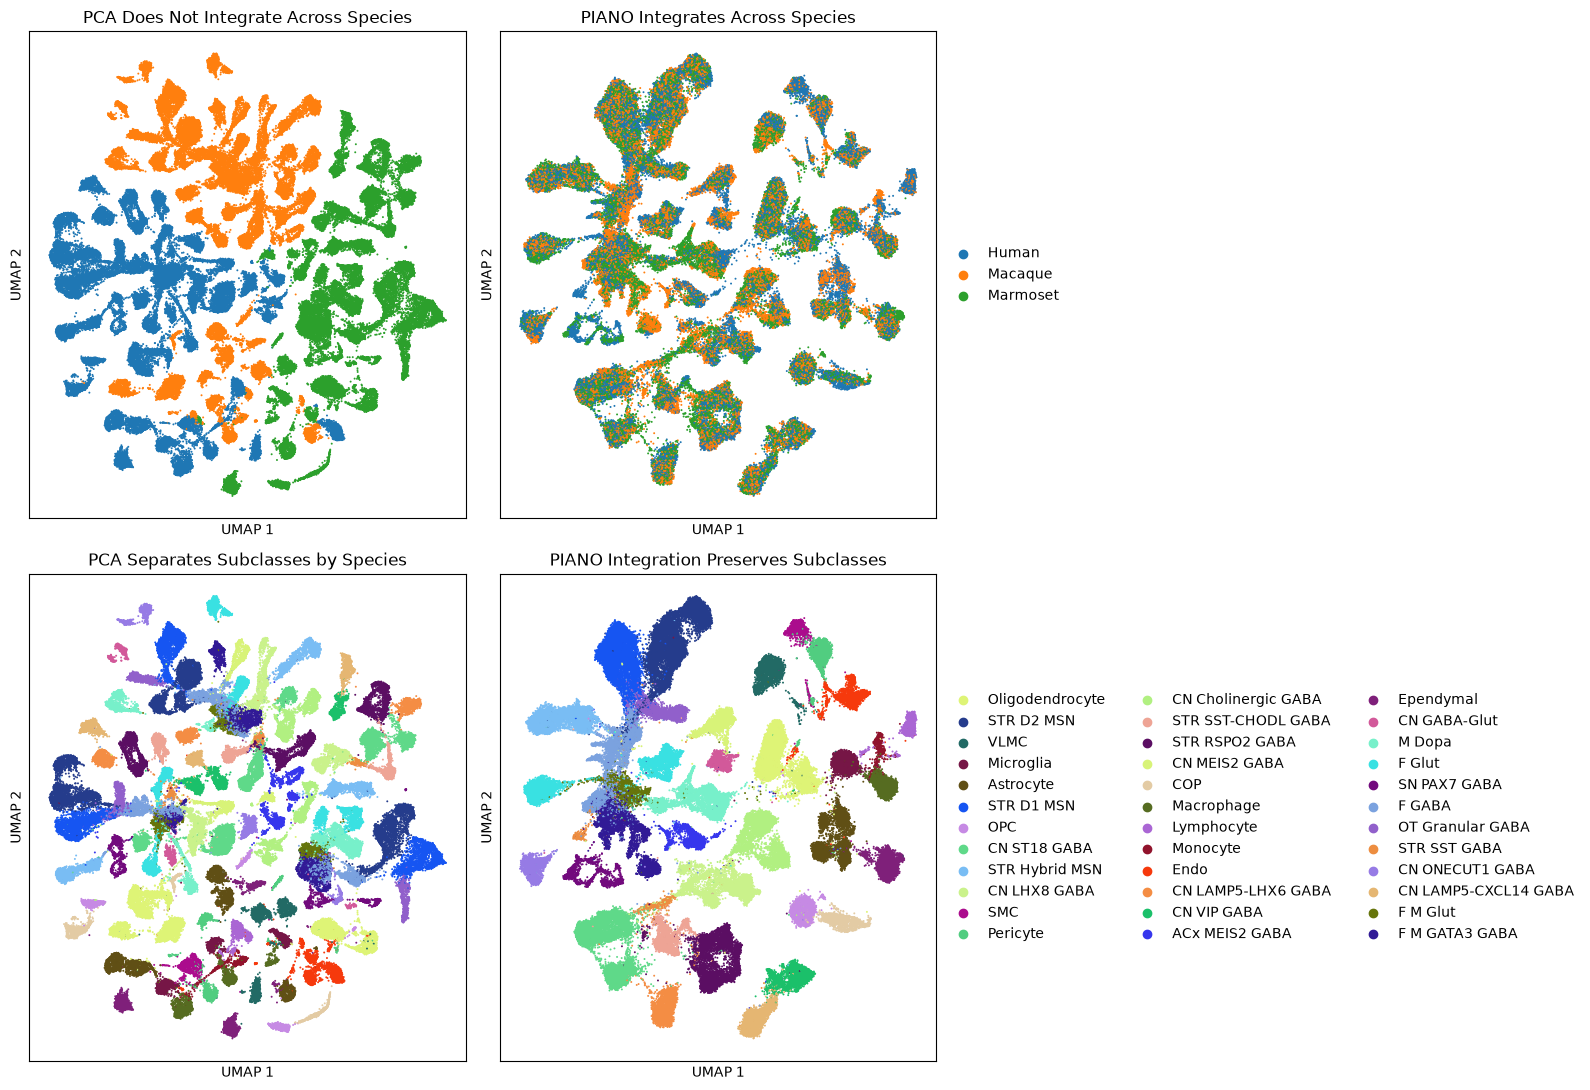

In [7]:
%matplotlib inline

plot_ad = combined[np.random.default_rng(0).permutation(combined.n_obs)].copy()
species_palette = {"Human": "#1f77b4", "Macaque": "#ff7f0e", "Marmoset": "#2ca02c"}
subclass_palette = dict(plot_ad.obs.drop_duplicates("Subclass").set_index("Subclass")["color_hex_subclass"])

panels = [
    ("X_umap_pca", "organism", species_palette, "none", "PCA Does Not Integrate Across Species"),
    ("X_umap_piano", "organism", species_palette, "right margin", "PIANO Integrates Across Species"),
    ("X_umap_pca", "Subclass", subclass_palette, "none", "PCA Separates Subclasses by Species"),
    ("X_umap_piano", "Subclass", subclass_palette, "right margin", "PIANO Integration Preserves Subclasses"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (basis, color, palette, legend_loc, title) in zip(axes.ravel(), panels):
    plot_ad.obsm["X_umap"] = plot_ad.obsm[basis]
    sc.pl.umap(plot_ad, color=color, palette=palette, ax=ax, show=False, title=title, legend_loc=legend_loc, size=8, frameon=True)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")


fig.tight_layout()
fig.savefig(OUT_DIR / "pca_vs_piano_umap.png", dpi=200, bbox_inches="tight")
plt.show()


## Optional: rebuild the processed files

Skip this if you downloaded the three species `.h5ad` files above. The cell below is the preprocessing we used.

It needs the raw species atlases and the Ensembl 114 ortholog table (not required for the tutorial itself):

- `Human_HMBA_basalganglia_AIT_pre-print.h5ad`
- `Macaque_HMBA_basalganglia_AIT_pre-print.h5ad`
- `Marmoset_HMBA_basalganglia_AIT_pre-print.h5ad`
- `Ensemble114_human_mouse_macaque_marmoset.csv`

Set `RAW_DIR` and `ORTHOLOG_CSV`, then run it. Output is written to `DATA_DIR`.


In [ ]:
import pandas as pd
from scipy.sparse import csr_matrix

# Raw HMBA basal ganglia atlases (one h5ad per species) and Ensembl ortholog table
RAW_DIR = Path("/path/to/HMBA_basalganglia_h5ads")
ORTHOLOG_CSV = Path("/path/to/Ensemble114_human_mouse_macaque_marmoset.csv")
DATA_DIR.mkdir(parents=True, exist_ok=True)

OBS_COLS = ["Neighborhood", "Class", "Subclass", "Group", "Cluster", "donor_id", "organism", "organism_sci", "color_hex_neighborhood", "color_hex_class", "color_hex_subclass", "color_hex_group"]
SPECIES_FILES = {"human": RAW_DIR / "Human_HMBA_basalganglia_AIT_pre-print.h5ad", "macaque": RAW_DIR / "Macaque_HMBA_basalganglia_AIT_pre-print.h5ad", "marmoset": RAW_DIR / "Marmoset_HMBA_basalganglia_AIT_pre-print.h5ad"}

# Keep 1:1, high-confidence human–macaque–marmoset orthologs
orth = pd.read_csv(ORTHOLOG_CSV, usecols=["Gene name", "Macaque gene name", "Macaque homology type", "Macaque orthology confidence [0 low, 1 high]", "White-tufted-ear marmoset gene name", "White-tufted-ear marmoset homology type", "White-tufted-ear marmoset orthology confidence [0 low, 1 high]"])
orth = orth[
    orth["Gene name"].notna()
    & orth["Macaque gene name"].notna()
    & (orth["Macaque homology type"] == "ortholog_one2one")
    & (orth["Macaque orthology confidence [0 low, 1 high]"] == 1)
    & orth["White-tufted-ear marmoset gene name"].notna()
    & (orth["White-tufted-ear marmoset homology type"] == "ortholog_one2one")
    & (orth["White-tufted-ear marmoset orthology confidence [0 low, 1 high]"] == 1)
].drop_duplicates()

# Map non-human gene symbols onto the human name used as the shared index
macaque_to_human = dict(zip(orth["Macaque gene name"], orth["Gene name"]))
marmoset_to_human = dict(zip(orth["White-tufted-ear marmoset gene name"], orth["Gene name"]))

def mapped_var_names(var_names, mapping):
    if mapping is None:
        return np.asarray(var_names)
    return np.array([mapping.get(g, "NOMATCH") for g in var_names])

# Genes present in all three atlases after mapping
var_names = {}
for species, path in SPECIES_FILES.items():
    adata_b = sc.read_h5ad(path, backed="r")
    var_names[species] = np.asarray(adata_b.var_names)
    del adata_b

human_genes = np.intersect1d(var_names["human"], orth["Gene name"])
macaque_genes = np.intersect1d(mapped_var_names(var_names["macaque"], macaque_to_human), orth["Gene name"])
marmoset_genes = np.intersect1d(mapped_var_names(var_names["marmoset"], marmoset_to_human), orth["Gene name"])
common_genes = np.intersect1d(human_genes, np.intersect1d(macaque_genes, marmoset_genes))
print(len(common_genes), "shared 1:1 orthologs present in all three species")

def subsample_cell_index(obs, n=N_PER_GROUP, seed=0):
    # Up to n cells from each Group (keep all if the Group is smaller)
    rng = np.random.default_rng(seed)
    keep = []
    for _, df in obs.groupby("Group", observed=True):
        if len(df) > n:
            keep.append(rng.choice(df.index.to_numpy(), size=n, replace=False))
        else:
            keep.append(df.index.to_numpy())
    return np.concatenate(keep)

def subset_species(path, mapping, common_genes, out_path):
    # backed='r' avoids loading the full atlas; only selected cells/genes come into memory
    src = sc.read_h5ad(path, backed="r")
    mapped = mapped_var_names(src.var_names, mapping)
    orig_var = np.asarray(src.var_names)[pd.Index(mapped).get_indexer(common_genes)]
    cells = subsample_cell_index(src.obs)

    adata = src[cells, orig_var].to_memory()
    adata.X = csr_matrix(src.raw[cells, orig_var].X, dtype=np.uint16)  # raw counts
    adata.raw = None
    adata.obs = adata.obs[OBS_COLS]
    adata.var_names = np.asarray(common_genes)  # human gene names in all three files
    if mapping is not None:
        adata.var["original_name"] = np.asarray(orig_var)
    adata.uns = {}
    adata.obsm.clear()
    adata.obsp.clear()
    adata.layers.clear()
    adata.write_h5ad(out_path)
    print(out_path.name, adata.shape)
    del adata, src

mappings = {"human": None, "macaque": macaque_to_human, "marmoset": marmoset_to_human}
for species, path in SPECIES_FILES.items():
    subset_species(
        path,
        mappings[species],
        common_genes,
        DATA_DIR / f"{species}_orthologs_subset_{N_PER_GROUP}_per_group.h5ad",
    )
